In [29]:
import os
import json
import uuid
from typing import TypedDict, List
from langchain_core.messages import HumanMessage
from langchain_core.tools import Tool
from langchain_community.utilities import SerpAPIWrapper
from langgraph.graph import StateGraph, END, START
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import PromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI

In [ ]:
import os
os.environ["GOOGLE_API_KEY"] = "api_key"

In [31]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0
)

In [32]:
MEMORY_FILE = "agent_memory.json"
class SharedResourcePool:
    def __init__(self):
        # Initialised LLM With Specific Parameters(temprature, top_p)
        self.llm = ChatGoogleGenerativeAI(model ="gemini-flash-lite-latest",
                             temperature=0.7,
                             max_output_tokens=1024,
                             google_api_key=os.environ['GOOGLE_API_KEY'])
 
        # Call _load to laod the filr from thr memory
        self.memory: List[str] = self._load_memory()
        
    @staticmethod
    def _safe_eval(expr: str) -> str:
        try:
            return str(eval(expr))
        except Exception as e:
            return f"Error evaluating expression: {e}"
 
    def _load_memory(self) -> List[str]:  #Load The Memory
        if os.path.exists(MEMORY_FILE):
            with open(MEMORY_FILE, "r") as f:
              return json.load(f)
        else:
            return []
 
    def remember(self, note: str):       #Append The Memory
        self.memory.append(note)
        with open(MEMORY_FILE, "w") as f:
            json.dump(self.memory, f, indent = 2)
 
    def recall(self, last_n: int = 5) -> str: # Recall The Memory
        if not self.memory:
            return "(no earlier notes)"
        return "\n".join(self.memory[-last_n:])
 

In [33]:
# Initialize the shared resource pool
resource_pool = SharedResourcePool()

In [34]:
SIZES  = {"small": 0.00, "medium": 0.50, "large": 1.00}
MILKS  = {"whole": 0.00, "skim": 0.00, "oat": 0.70, "almond": 0.70, "soy": 0.60}
EXTRAS = {"extra shot": 0.75, "vanilla syrup": 0.50, "caramel syrup": 0.50, "whipped cream": 0.50}

MENU = {
    "latte":            {"category": "Espresso Drinks", "base_price": 4.50, "needs_size": True,  "milk": "required", "in_stock": True},
    "cappuccino":       {"category": "Espresso Drinks", "base_price": 4.25, "needs_size": True,  "milk": "required", "in_stock": True},
    "flat white":       {"category": "Espresso Drinks", "base_price": 4.75, "needs_size": True,  "milk": "required", "in_stock": True},
    "mocha":            {"category": "Espresso Drinks", "base_price": 5.00, "needs_size": True,  "milk": "required", "in_stock": False},  # OUT OF STOCK
    "caramel macchiato":{"category": "Specialty Drinks", "base_price": 5.25, "needs_size": True,  "milk": "required", "in_stock": False},  # OUT OF STOCK
    "americano":        {"category": "Black Coffee",    "base_price": 3.25, "needs_size": True,  "milk": "none",     "in_stock": True},
    "cold brew":        {"category": "Black Coffee",    "base_price": 4.00, "needs_size": True,  "milk": "optional", "in_stock": True},
    "green tea":        {"category": "Tea",             "base_price": 3.00, "needs_size": True,  "milk": "none",     "in_stock": True},
    "blueberry muffin": {"category": "Bakery",          "base_price": 3.25, "needs_size": False, "milk": "none",     "in_stock": True},
    "croissant":        {"category": "Bakery",          "base_price": 3.50, "needs_size": False, "milk": "none",     "in_stock": True},
}

In [35]:
def get_menu(category=None):
    menu = {
        item: details
        for item, details in MENU.items()
        if category is None or details["category"].lower() == category.lower()
    }

    return {
        "menu": menu,
        "sizes": SIZES,
        "milks": MILKS,
        "extras": EXTRAS
    }

In [36]:
# Tool2
def check_availability(item):

    item = item.lower()

    if item not in MENU:
        return False

    return MENU[item]["in_stock"]

In [37]:
def validate_order(item, size, milk, extras):

    item = item.lower()
    size = size.lower()
    milk = milk.lower()

    if item not in MENU:
        return {
            "valid": False,
            "reason": "Item is not available on the menu."
        }

    if not MENU[item]["in_stock"]:
        return {
            "valid": False,
            "reason": f"{item.title()} is currently out of stock."
        }

    if MENU[item]["needs_size"] and size not in SIZES:
        return {
            "valid": False,
            "reason": "Invalid size."
        }

    if MENU[item]["milk"] == "required" and milk not in MILKS:
        return {
            "valid": False,
            "reason": "Invalid milk type."
        }

    for extra in extras:
        if extra.lower() not in EXTRAS:
            return {
                "valid": False,
                "reason": f"{extra} is not available."
            }

    price = MENU[item]["base_price"]

    if MENU[item]["needs_size"]:
        price += SIZES[size]

    if milk in MILKS:
        price += MILKS[milk]

    for extra in extras:
        price += EXTRAS[extra.lower()]

    return {
        "valid": True,
        "reason": "Order is valid.",
        "price": round(price, 2)
    }

In [38]:
# tool4
def update_cart(cart, action, item=None):

    if action == "add":

        cart.append(item)

    elif action == "remove":

        if item is not None:

            for cart_item in cart:

                if cart_item["item"] == item["item"]:

                    cart.remove(cart_item)
                    break

    elif action == "clear":

        cart.clear()

    elif action == "modify":

        if item is not None:

            for i in range(len(cart)):

                if cart[i]["item"] == item["item"]:

                    cart[i] = item
                    break

    return cart

In [39]:
# tool5
def calculate_total(cart):

    subtotal = 0

    for item in cart:

        subtotal += (
            item["price"] *
            item["quantity"]
        )

    tax = round(subtotal * 0.05, 2)

    total = round(
        subtotal + tax,
        2
    )

    return {
        "subtotal": subtotal,
        "tax": tax,
        "total": total
    }

In [40]:
# tool6

def place_order(cart, customer_name="Customer"):

    if len(cart) == 0:

        return {
            "success": False,
            "message": "Cannot place an empty order."
        }

    order_id = (
        "ORD-" +
        uuid.uuid4().hex[:6].upper()
    )

    return {
        "success": True,
        "order_id": order_id,
        "pickup_time": "8 minutes",
        "customer": customer_name
    }

In [41]:
class State(dict):

    messages: list
    intent: str
    cart: list
    order_id: str
    evaluation: dict
    retry_count: int
    response: str

In [42]:
def planner_agent(state):

    user_message = state["messages"][-1].content

    prompt = f"""
    Determine the intent of the user's request by selecting exactly one category from:

    browse_menu
    build_order
    place_order

    User Input:
    {user_message}

    Output only the intent name and nothing else.

    """

    response = llm.invoke(prompt)

    content = response.content

    if isinstance(content, list):
        content = " ".join(
            part.get("text", "")
            if isinstance(part, dict)
            else str(part)
            for part in content
        )

    intent = content.strip().lower()

    if "browse_menu" in intent:
        state["intent"] = "browse_menu"

    elif "build_order" in intent:
        state["intent"] = "build_order"

    elif "place_order" in intent:
        state["intent"] = "place_order"

    else:
        state["intent"] = "browse_menu"

    return state

In [43]:
# Menu Agent
def menu_agent(state: State) -> State:

    user_message = state["messages"][-1].content

    menu_data = get_menu()

    menu = menu_data["menu"]
    sizes = menu_data["sizes"]
    milks = menu_data["milks"]
    extras = menu_data["extras"]

    menu_text = ""

    for key, item in menu.items():

        availability = (
            "Available"
            if check_availability(key)
            else "Out of stock"
        )
        size_list = ", ".join(sizes.keys())
        milk_list = ", ".join(milks.keys())
        extra_list = ", ".join(extras.keys())

        menu_text += f"""
Drink: {key.title()}

Sizes:
{size_list}

Milk:
{milk_list}

Extras:
{extra_list}

Availability:
{availability}

--------------------
"""

    prompt = f"""
    You are responsible for helping customers with menu-related questions.

Use only the menu details supplied below to answer the customer's request.

Never make up or infer:

- drink names
- costs
- available sizes
- milk choices
- extra ingredients
- item availability

Menu Data:

{menu_text}

Customer Message:

{user_message}

Respond clearly, professionally, and only with information found in the menu data.
    """

    response = llm.invoke(prompt)

    content = response.content

    if isinstance(content, list):

        parts = []

        for part in content:

            if isinstance(part, dict):

                if "text" in part:
                    parts.append(part["text"])

            else:
                parts.append(str(part))

        content = " ".join(parts)

    state["response"] = content

    return state

In [44]:
# Order Agent
def order_agent(state: State) -> State:

    user_message = state["messages"][-1].content

    menu_data = get_menu()
    menu = menu_data["menu"]

    prompt = f"""
You are the Order Processing Agent for a coffee shop.

Analyze the customer's message and determine the order details based on the menu data provided.

Menu Data:

{menu}

Customer Message:

{user_message}

Identify and return:

- item
- size
- milk
- extras
- quantity

Guidelines:

- Return "missing_size" if no size is specified.
- Return "missing_milk" if no milk choice is specified.
- If quantity is not provided, use a default value of 1.
- Do not guess unavailable menu options.
- Use only values present in the menu data.

Provide the extracted information in a concise and easy-to-read format.
"""

    response = llm.invoke(prompt)

    content = response.content

    if isinstance(content, list):

        parts = []

        for part in content:

            if isinstance(part, dict):

                if "text" in part:
                    parts.append(part["text"])

            else:
                parts.append(str(part))

        content = " ".join(parts)

    text = str(content).lower()


    if "missing_size" in text:

        state["response"] = (
            "What size would you like? "
            "Small, Medium, or Large?"
        )

        return state

    if "missing_milk" in text:

        state["response"] = (
            "Which milk would you like? "
            "Whole, Skim, Oat, or Almond?"
        )

        return state


    item_name = None

    for item in menu:

        if item in text:
            item_name = item
            break

    if item_name is None:

        state["response"] = (
            "Sorry, I couldn't find that drink "
            "on our menu."
        )

        return state


    size = None

    for s in SIZES.keys():

        if s in text:
            size = s
            break

    if size is None:

        state["response"] = (
            "What size would you like? "
            "Small, Medium, or Large?"
        )

        return state


    milk = None

    for m in MILKS.keys():

        if m in text:
            milk = m
            break

    if milk is None:

        state["response"] = (
            "Which milk would you like? "
            "Whole, Skim, Oat, or Almond?"
        )

        return state


    quantity = 1

    if "2" in text or "two" in text:
        quantity = 2

    elif "3" in text or "three" in text:
        quantity = 3


    extras = []

    for extra in EXTRAS.keys():

        if extra in text:
            extras.append(extra)


    validation = validate_order(
        item_name,
        size,
        milk,
        extras
    )

    if not validation["valid"]:

        state["response"] = validation["reason"]

        return state


    cart_item = {
        "item": item_name,
        "size": size,
        "milk": milk,
        "extras": extras,
        "quantity": quantity,
        "price": validation["price"]
    }


    state["cart"] = update_cart(
        state["cart"],
        "add",
        cart_item
    )


    state["response"] = (
        f"{quantity} × {size.title()} "
        f"{item_name.title()}"
        f"({milk} milk) has been added to your cart.\n"
        f"Price: ₹{validation['price'] * quantity}\n\n"
        f"Would you like anything else?"
    )

    return state

In [45]:
# Placement Agent
def placement_agent(state: State) -> State:

    cart = state.get(
        "cart",
        []
    )


    if len(cart) == 0:

        state["response"] = (
            "Your cart is empty. "
            "Please tell me what you would like to order."
        )

        return state


    total = calculate_total(cart)


    user_message = (
        state["messages"][-1].content.lower()
    )

    confirmation_words = [
        "yes",
        "confirm",
        "confirmed",
        "go ahead",
        "place it",
        "place my order",
        "order it"
    ]

    confirmed = any(
        word in user_message
        for word in confirmation_words
    )


    if not confirmed:

        cart_text = ""

        for item in cart:

            cart_text += (
                f"{item['quantity']} × "
                f"{item['item'].title()} "
                f"({item['size']}, "
                f"{item['milk']}) "
                f"- ₹{item['price']} each\n"
            )

        state["response"] = f"""
Your current cart:

{cart_text}

Subtotal: ₹{total["subtotal"]}
Tax: ₹{total["tax"]}
Total: ₹{total["total"]}

Would you like me to place this order?
""".strip()

        return state


    result = place_order(
        cart,
        "Customer"
    )

    if not result["success"]:

        state["response"] = result["message"]

        return state


    state["order_id"] = result["order_id"]

    state["response"] = (
        f"Order {result['order_id']} placed successfully. "
        f"Your total is ₹{total['total']}. "
        f"Ready in about {result['pickup_time']}."
    )

    return state

In [46]:
def evaluator_agent(state):

    response_text = state["response"]

    prompt = f"""
You are an Evaluation Agent responsible for validating responses generated by a coffee shop ordering system.

Response to Evaluate:

{response_text}

Assess the response based on the following checks:

1. Correctness
   - Information must match the available menu and tool data.

2. Coverage
   - Required details should be present and sufficiently addressed.

3. No Unsupported Information
   - Do not allow invented products, prices, offers, availability statuses, or order details.

4. Intent Fulfillment
   - The response should appropriately satisfy the customer's request.

Return only one of these formats:

verdict: approved
score: 5
feedback: The response meets all evaluation requirements.

OR

verdict: rejected
score: 2
feedback: Describe the identified problems and why the response fails the evaluation.
"""

    response = llm.invoke(prompt)

    evaluation_text = response.content

    # Gemini may return content as a list
    if isinstance(evaluation_text, list):

        parts = []

        for part in evaluation_text:

            if isinstance(part, dict):

                if "text" in part:
                    parts.append(part["text"])

            else:
                parts.append(str(part))

        evaluation_text = " ".join(parts)

    evaluation_text = str(evaluation_text).strip()


    if "verdict: approved" in evaluation_text.lower():

        verdict = "approved"

    else:

        verdict = "rejected"


    score = 1

    for number in ["5", "4", "3", "2", "1"]:

        if f"score: {number}" in evaluation_text.lower():

            score = int(number)
            break


    feedback = evaluation_text

    if "feedback:" in evaluation_text.lower():

        feedback = evaluation_text.split(
            "feedback:",
            1
        )[1].strip()


    state["evaluation"] = {
        "verdict": verdict,
        "score": score,
        "feedback": feedback
    }

    return state

In [47]:
def planner_router(state: State):

    intent = state.get(
        "intent",
        "browse_menu"
    )

    if intent == "browse_menu":

        return "menu_agent"

    elif intent == "build_order":

        return "order_agent"

    elif intent == "place_order":

        return "placement_agent"

    return "menu_agent"

In [48]:
def evaluator_router(state: State):

    evaluation = state.get(
        "evaluation",
        {}
    )

    verdict = evaluation.get(
        "verdict",
        "approved"
    )

    retry_count = state.get(
        "retry_count",
        0
    )


    if verdict == "approved":

        return "end"


    if retry_count < 2:

        return "retry"


    return "end"

In [49]:
def retry_agent(state: State) -> State:

    retry_count = state.get(
        "retry_count",
        0
    )

    state["retry_count"] = (
        retry_count + 1
    )

    return state

In [50]:
graph = StateGraph(State)

graph.add_node(
    "planner",
    planner_agent
)

graph.add_node(
    "menu_agent",
    menu_agent
)

graph.add_node(
    "order_agent",
    order_agent
)

graph.add_node(
    "placement_agent",
    placement_agent
)

graph.add_node(
    "evaluator",
    evaluator_agent
)

graph.add_node(
    "retry",
    retry_agent
)

In [51]:
graph.add_edge(
    START,
    "planner"
)

graph.add_conditional_edges(
    "planner",
    planner_router,
    {
        "menu_agent": "menu_agent",
        "order_agent": "order_agent",
        "placement_agent": "placement_agent"
    }
)

graph.add_edge(
    "menu_agent",
    "evaluator"
)

graph.add_edge(
    "order_agent",
    "evaluator"
)

graph.add_edge(
    "placement_agent",
    "evaluator"
)

graph.add_conditional_edges(
    "evaluator",
    evaluator_router,
    {
        "retry": "retry",
        "end": END
    }
)

graph.add_edge(
    "retry",
    "planner"
)

In [52]:
runnable = graph.compile()

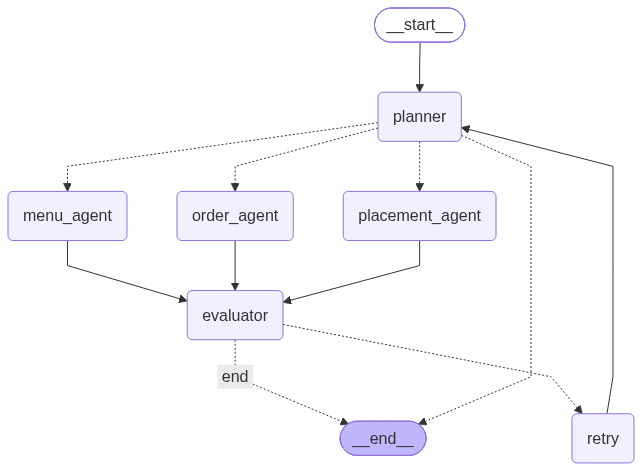

In [53]:
from IPython.display import Image, display
display(
    Image(
        runnable.get_graph().draw_mermaid_png()
    )
)

In [54]:
result = runnable.invoke({
    "messages": [
        HumanMessage(
            content="Show me your menu"
        )
    ],
    "cart": [],
    "retry_count": 0
})

print("RESPONSE:")
print(result["response"])

RESPONSE:
Here is our menu based on the currently available items and details:

* **Latte** (Available)
  * Sizes: small, medium, large
  * Milk: whole, skim, oat, almond, soy
  * Extras: extra shot, vanilla syrup, caramel syrup, whipped cream

* **Cappuccino** (Available)
  * Sizes: small, medium, large
  * Milk: whole, skim, oat, almond, soy
  * Extras: extra shot, vanilla syrup, caramel syrup, whipped cream

* **Flat White** (Available)
  * Sizes: small, medium, large
  * Milk: whole, skim, oat, almond, soy
  * Extras: extra shot, vanilla syrup, caramel syrup, whipped cream

* **Mocha** (Out of stock)
  * Sizes: small, medium, large
  * Milk: whole, skim, oat, almond, soy
  * Extras: extra shot, vanilla syrup, caramel syrup, whipped cream

* **Caramel Macchiato** (Out of stock)
  * Sizes: small, medium, large
  * Milk: whole, skim, oat, almond, soy
  * Extras: extra shot, vanilla syrup, caramel syrup, whipped cream

* **Americano** (Available)
  * Sizes: small, medium, large
  * Mil

In [55]:
result = runnable.invoke({
    "messages": [
        HumanMessage(
            content="What are the prices of all these items?"
        )
    ],
    "cart": [],
    "retry_count": 0
})

print("RESPONSE:")
print(result["response"])

RESPONSE:
I am sorry, but the menu details provided do not include the prices for any of the items.


In [56]:
result = runnable.invoke({
    "messages": [
        HumanMessage(
            content="Get me a cappuccino."
        )
    ],
    "cart": [],
    "retry_count": 0
})

print("RESPONSE:")
print(result["response"])

RESPONSE:
What size would you like? Small, Medium, or Large?


In [59]:
result = runnable.invoke({
    "messages": [
        HumanMessage(
            content="I want a medium cappuccino."
        )
    ],
    "cart": [],
    "retry_count": 0
})

cart = result["cart"]

print(result["response"])

Which milk would you like? Whole, Skim, Oat, or Almond?


In [60]:
result = runnable.invoke({
    "messages": [
        HumanMessage(
            content="I want a medium cappuccino with oat milk."
        )
    ],
    "cart": cart,
    "retry_count": 0
})

print("RESPONSE:")
print(result["response"])

print("\nCART:")
print(result["cart"])

RESPONSE:
1 × Medium Cappuccino(oat milk) has been added to your cart.
Price: ₹5.45

Would you like anything else?

CART:
[{'item': 'cappuccino', 'size': 'medium', 'milk': 'oat', 'extras': [], 'quantity': 1, 'price': 5.45}, {'item': 'cappuccino', 'size': 'medium', 'milk': 'oat', 'extras': [], 'quantity': 1, 'price': 5.45}, {'item': 'cappuccino', 'size': 'medium', 'milk': 'oat', 'extras': [], 'quantity': 1, 'price': 5.45}]


In [63]:
result = runnable.invoke({
    "messages": [
        HumanMessage(
            content="No place my order."
        )
    ],
    "cart": cart,
    "retry_count": 0
})

print("RESPONSE:")
print(result["response"])

RESPONSE:
Order ORD-1916FA placed successfully. Your total is ₹17.17. Ready in about 8 minutes.


In [ ]:
from langchain_core.messages import HumanMessage

print("☕ Coffee Ordering Assistant")
print("Type 'exit' to stop.")
print("-" * 40)

conversation = ""
cart = []
retry_count = 0

while True:

    user_input = input("You: ")

    if user_input.lower() == "exit":
        print("Assistant: Thank you! Goodbye ☕")
        break

    # Add new user message to conversation
    conversation += f"\nUser: {user_input}"

    # Send complete conversation to the graph
    result = runnable.invoke({
        "messages": [
            HumanMessage(content=conversation)
        ],
        "cart": cart,
        "retry_count": retry_count
    })

    response = result.get("response", "")

    # Update state
    cart = result.get("cart", cart)
    retry_count = result.get("retry_count", retry_count)

    print("\nAssistant:")
    print(response)

    # Add assistant response to conversation
    conversation += f"\nAssistant: {response}"

    print("\n" + "-" * 40)

☕ Coffee Ordering Assistant
Type 'exit' to stop.
----------------------------------------

Assistant:
Hello! Here is our menu:

* **Latte** - Available
* **Cappuccino** - Available
* **Flat White** - Available
* **Mocha** - Out of stock
* **Caramel Macchiato** - Out of stock
* **Americano** - Available
* **Cold Brew** - Available
* **Green Tea** - Available
* **Blueberry Muffin** - Available
* **Croissant** - Available

**Available Sizes:** small, medium, large  
**Available Milk Options:** whole, skim, oat, almond, soy  
**Available Extras:** extra shot, vanilla syrup, caramel syrup, whipped cream

----------------------------------------

Assistant:
What size would you like? Small, Medium, or Large?

----------------------------------------

Assistant:
Which milk would you like? Whole, Skim, Oat, or Almond?

----------------------------------------

Assistant:
1 × Large Latte(almond milk) has been added to your cart.
Price: ₹6.2

Would you like anything else?

-----------------------